# Phishing URL Behaviour Classification

**Exploratory analysis and preprocessing.** Abdul Rehman, LearnDepth capstone. The dataset is [Malicious URLs dataset](https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset), curated by sid321axn. This notebook runs in the project folder alongside `prepare_data.py` and `features.py`.


## 1. Inspect the public CSV
The public file contains four categories. We keep only benign and phishing URLs for this binary project. The CSV must be saved as `candidate_data/malicious_phish.csv`.


In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlsplit
from prepare_data import load_clean_data
from features import extract_features

raw = pd.read_csv("candidate_data/malicious_phish.csv", usecols=["url", "type"])
print("Raw rows and columns:", raw.shape)
print("Original class counts:")
print(raw["type"].value_counts())
print("Missing values:")
print(raw.isna().sum())


Raw rows and columns: (651191, 2)
Original class counts:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64
Missing values:
url     0
type    0
dtype: int64


In [18]:
selected = raw.loc[raw["type"].isin(["benign", "phishing"])].copy()
print("Selected rows:", len(selected))
print(selected["type"].value_counts())
print("Repeated raw URLs:", selected["url"].duplicated().sum())


Selected rows: 522214
type
benign      428103
phishing     94111
Name: count, dtype: int64
Repeated raw URLs: 48


## 2. Apply the project cleaning code
`load_clean_data()` normalizes schemes and handles conflicting or repeated URL strings. As in `train_model.py`, feature extraction skips malformed URLs. Here `0` means phishing and `1` means benign.


In [19]:
cleaned = load_clean_data()
feature_rows = []
kept_indices = []
for index, url in enumerate(cleaned["url"]):
    try:
        row = extract_features(url)
    except ValueError:
        continue
    kept_indices.append(index)
    feature_rows.append(row)

data = cleaned.iloc[kept_indices].reset_index(drop=True)
X = pd.DataFrame(feature_rows)
print("Unparseable URLs skipped:", len(cleaned) - len(data))
print("Usable rows:", len(data))
print("Final class counts:")
print(data["label"].value_counts().sort_index())
print("Six feature columns:", X.columns.tolist())


Conflicting URLs after prefix cleanup: 4049
Unparseable URLs skipped: 18
Usable rows: 513189
Final class counts:
label
0     89471
1    423718
Name: count, dtype: int64
Six feature columns: ['url_length', 'digit_ratio', 'special_char_count', 'hostname_length', 'hostname_digit_ratio', 'hostname_dot_count']


## 3. Class balance
The phishing category is smaller. An always-benign predictor can achieve deceptively high accuracy, so the model is also judged by phishing precision, recall and F1.


Phishing share (%): 17.43


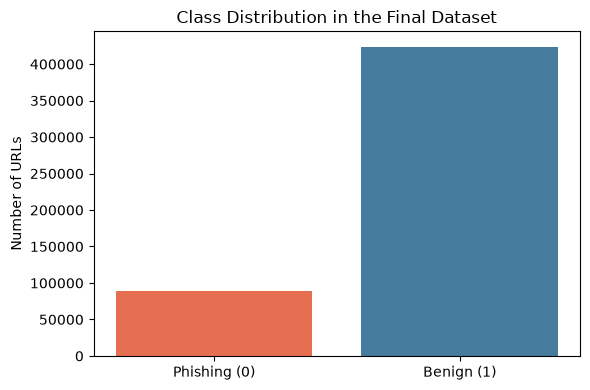

In [20]:
counts = data["label"].value_counts().reindex([0, 1], fill_value=0)
print("Phishing share (%):", round(100 * counts.loc[0] / len(data), 2))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Phishing (0)", "Benign (1)"], counts.tolist(), color=["#e76f51", "#457b9d"])
ax.set_ylabel("Number of URLs")
ax.set_title("Class Distribution in the Final Dataset")
fig.tight_layout()
plt.show()


## 4. Compare structural features
A median is the midpoint of the values. Comparing medians suggests which features may be useful, but these comparisons alone do not prove a URL is phishing.


In [21]:
feature_table = X.assign(label=data["label"].to_numpy())
print("Median feature values by class:")
print(feature_table.groupby("label").median().round(3))
print("Missing numeric features:")
print(X.isna().sum())


Median feature values by class:
       url_length  digit_ratio  special_char_count  hostname_length  \
label                                                                 
0            41.0        0.000                 8.0             17.0   
1            54.0        0.027                 9.0             15.0   

       hostname_digit_ratio  hostname_dot_count  
label                                            
0                       0.0                 2.0  
1                       0.0                 1.0  
Missing numeric features:
url_length              0
digit_ratio             0
special_char_count      0
hostname_length         0
hostname_digit_ratio    0
hostname_dot_count      0
dtype: int64


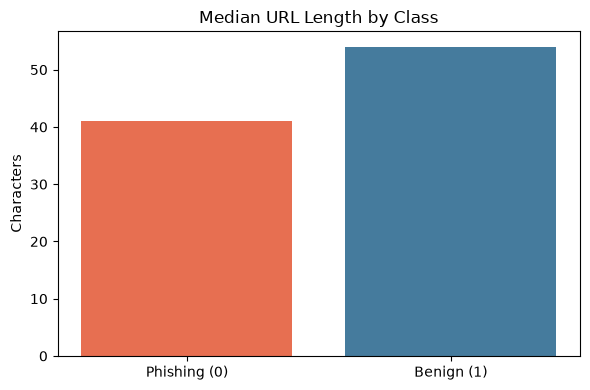

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
medians = feature_table.groupby("label")["url_length"].median().reindex([0, 1])
ax.bar(["Phishing (0)", "Benign (1)"], medians.tolist(), color=["#e76f51", "#457b9d"])
ax.set_title("Median URL Length by Class")
ax.set_ylabel("Characters")
fig.tight_layout()
plt.show()


## 5. Model evaluation summary

We selected an unweighted Decision Tree and chose a phishing cutoff of 0.30 using validation data. Training and test URLs were separated by hostname.

On 102,639 held-out test URLs, accuracy was **86.81%**, compared with an always-benign baseline of **82.57%**. Phishing precision was **0.612**, recall **0.666**, F1-score **0.638**, and ROC-AUC **0.879**.

The model detected **11,918** phishing URLs and missed **5,977**. It falsely flagged **7,564** benign URLs and correctly identified **77,180** benign URLs. The lower cutoff caught more phishing URLs but caused more false alarms.

**Limitation:** The model examines URL text only. Its prediction cannot verify whether a website is safe.

Dataset: [Malicious URLs dataset](https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset). Related work: [Sahingoz et al. (2019)](https://doi.org/10.1016/j.eswa.2018.09.029).

In [23]:
print("URL length distribution:")
print(X["url_length"].describe(percentiles=[0.90, 0.95, 0.99]).round(2))

print("\nFive longest URLs (length and label only):")
print(X.assign(label=data["label"]).nlargest(5, "url_length")[["url_length", "label"]])

relationships = X.copy()
relationships["is_phishing"] = (data["label"] == 0).astype(int)

print("\nFeature relationships with phishing:")
print(
    relationships.corr(numeric_only=True)["is_phishing"]
    .drop("is_phishing")
    .sort_values(ascending=False)
    .round(3)
)

URL length distribution:
count    513189.00
mean         62.49
std          43.38
min           9.00
90%         104.00
95%         128.00
99%         242.00
max        2183.00
Name: url_length, dtype: float64

Five longest URLs (length and label only):
        url_length  label
442363        2183      1
358187        2081      1
409292        1779      0
264242        1696      1
414256        1641      0

Feature relationships with phishing:
hostname_dot_count      0.196
hostname_length         0.079
hostname_digit_ratio    0.039
digit_ratio            -0.102
url_length             -0.122
special_char_count     -0.129
Name: is_phishing, dtype: float64


### EDA interpretation

The 99th percentile of URL length is 242 characters, but the longest URL has 2,183. Very long URLs occur in both classes, so I kept them rather than assuming they were errors.

The strongest individual linear relationship with phishing is hostname dot count (0.196). All six correlations are small. These relationships describe this dataset; they do not prove that any one URL is phishing.